# Proyek Analisis Data: Air Quality Dataset
- **Nama:** Amalia Putri
- **Email:** amaliaput1208@gmail.com
- **ID Dicoding:** DS009B6X0161

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Stasiun mana yang punya rata-rata konsentrasi PM2.5 tertinggi dan terendah sepanjang tahun 2016, dan berapa selisihnya?
- **Pertanyaan 2:** Pada jam berapa dan di musim apa rata-rata PM2.5 paling tinggi selama periode Maret 2013 sampai Februari 2017, dan berapa selisihnya dibanding jam dan musim terendah?

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load data PRSA dari 12 stasiun

In [2]:
files = sorted(glob.glob("data/PRSA_Data_*.csv"))
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
print(df.shape)
print(df["station"].unique())
df.head()

(420768, 18)
['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Dataset berisi 420.768 baris dan 18 kolom dari 12 stasiun pemantauan di Beijing, masing-masing 35.064 baris.
- Data berupa pengukuran per jam dari 1 Maret 2013 sampai 28 Februari 2017.
- Kolom waktu masih terpisah (year, month, day, hour) dan kolom `No` hanya nomor urut.

### Assessing Data

#### Identifying missing value, data type, and outlier problem

In [3]:
df.info()
print(df.isna().sum())
print("Duplikat:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB
No             0
year           0
month      

In [4]:
print(df[["PM2.5", "PM10", "SO2", "CO"]].describe())
print("Jumlah PM2.5 = 999:", (df["PM2.5"] == 999).sum())
print("Jumlah PM10 = 999:", (df["PM10"] == 999).sum())

               PM2.5           PM10            SO2             CO
count  412029.000000  414319.000000  411747.000000  400067.000000
mean       79.793428     104.602618      15.830835    1230.766454
std        80.822391      91.772426      21.650603    1160.182716
min         2.000000       2.000000       0.285600     100.000000
25%        20.000000      36.000000       3.000000     500.000000
50%        55.000000      82.000000       7.000000     900.000000
75%       111.000000     145.000000      20.000000    1500.000000
max       999.000000     999.000000     500.000000   10000.000000
Jumlah PM2.5 = 999: 1
Jumlah PM10 = 999: 3


**Steps to Take:**
- Menggabungkan kolom year, month, day, dan hour menjadi satu kolom datetime, lalu menghapus kolom `No` yang hanya nomor urut.
- Mengisi missing value pada kolom polutan dan cuaca menggunakan interpolasi per stasiun.
- Mengisi missing value pada kolom `wd` menggunakan nilai terdekat per stasiun.
- Mempertahankan nilai ekstrem (outlier) karena lonjakan polusi bisa terjadi secara nyata, bukan kesalahan data.

**Insight:**
- Missing value terbanyak ada di kolom CO (20.701), O3 (13.277), NO2 (12.116), SO2 (9.021), PM2.5 (8.739), PM10 (6.449), dan wd (1.822). Kolom cuaca hanya kehilangan sekitar 300-400 baris.
- Tidak ada data duplikat.
- Kolom waktu belum bertipe datetime karena masih terpisah menjadi empat kolom.
- PM2.5 dan PM10 memiliki nilai maksimum 999 (hanya 1 baris PM2.5 dan 3 baris PM10), jauh di atas rata-ratanya (PM2.5 sekitar 80). Jumlahnya sangat sedikit sehingga tidak memengaruhi rata-rata secara berarti.

### Cleaning Data

#### Fixing datetime problem

In [5]:
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.drop(columns=["No"])
df = df.sort_values(["station", "datetime"]).reset_index(drop=True)
df[["station", "datetime"]].head()

,station,datetime
0,Aotizhongxin,2013-03-01 00:00:00
1,Aotizhongxin,2013-03-01 01:00:00
2,Aotizhongxin,2013-03-01 02:00:00
3,Aotizhongxin,2013-03-01 03:00:00
4,Aotizhongxin,2013-03-01 04:00:00


**Insight:**
- Kolom year, month, day, dan hour berhasil digabung menjadi satu kolom datetime, sehingga data bisa diurutkan dan dianalisis berdasarkan waktu.
- Kolom `No` dihapus karena hanya berisi nomor urut dan tidak dipakai dalam analisis.
- Data diurutkan per stasiun dan waktu supaya proses interpolasi di tahap berikutnya berjalan benar.

#### Fixing missing value problem

In [6]:
num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
df[num_cols] = df.groupby("station")[num_cols].transform(lambda x: x.interpolate().ffill().bfill())
df["wd"] = df.groupby("station")["wd"].transform(lambda x: x.ffill().bfill())
df.isna().sum()

,0
year,0
month,0
day,0
hour,0
PM2.5,0
PM10,0
SO2,0
NO2,0
CO,0
O3,0


**Insight:**
- Missing value pada kolom polutan dan cuaca diisi dengan interpolasi per stasiun, sehingga nilai yang diisi tetap berasal dari stasiun yang sama dan tidak tercampur antar lokasi.
- Missing value pada kolom `wd` diisi dengan nilai terdekat per stasiun.
- Setelah cleaning, tidak ada lagi missing value pada seluruh kolom.
- Nilai ekstrem pada PM2.5 dan PM10 tetap dipertahankan karena jumlahnya sangat sedikit dan lonjakan polusi bisa terjadi secara nyata.

## Exploratory Data Analysis (EDA)

### Explore rata-rata PM2.5 per stasiun tahun 2016

In [7]:
df_2016 = df[df["datetime"].dt.year == 2016]
pm_station = df_2016.groupby("station")["PM2.5"].mean().sort_values(ascending=False)
print(pm_station)
print("Tertinggi:", pm_station.idxmax(), round(pm_station.max(), 2))
print("Terendah:", pm_station.idxmin(), round(pm_station.min(), 2))
print("Selisih:", round(pm_station.max() - pm_station.min(), 2))

station
Dongsi           80.180556
Wanshouxigong    78.112933
Gucheng          77.437443
Guanyuan         77.132514
Nongzhanguan     76.096539
Aotizhongxin     74.236680
Tiantan          73.801116
Shunyi           72.223588
Wanliu           71.433117
Dingling         61.701218
Changping        61.665699
Huairou          60.919627
Name: PM2.5, dtype: float64
Tertinggi: Dongsi 80.18
Terendah: Huairou 60.92
Selisih: 19.26


**Insight:**
- Pada tahun 2016, Dongsi memiliki rata-rata PM2.5 tertinggi (80,18 µg/m³), sedangkan Huairou terendah (60,92 µg/m³), dengan selisih sekitar 19,26 µg/m³.
- Stasiun dengan PM2.5 tertinggi (Dongsi, Wanshouxigong, Gucheng, Guanyuan) berada di kisaran 77-80 µg/m³, sedangkan tiga stasiun terendah (Dingling, Changping, Huairou) berada di kisaran 61-62 µg/m³.
- Semua stasiun memiliki rata-rata di atas 60 µg/m³, jauh di atas batas tahunan WHO sebesar 5 µg/m³.

### Explore rata-rata PM2.5 berdasarkan jam dan musim

In [8]:
df["hour"] = df["datetime"].dt.hour
df["month"] = df["datetime"].dt.month

def get_season(m):
    if m in [12, 1, 2]:
        return "Winter"
    elif m in [3, 4, 5]:
        return "Spring"
    elif m in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month"].apply(get_season)

pm_hour = df.groupby("hour")["PM2.5"].mean()
pm_season = df.groupby("season")["PM2.5"].mean().sort_values(ascending=False)

print(pm_hour.round(2))
print(pm_season.round(2))
print("Jam tertinggi:", pm_hour.idxmax(), round(pm_hour.max(), 2))
print("Jam terendah:", pm_hour.idxmin(), round(pm_hour.min(), 2))
print("Musim tertinggi:", pm_season.idxmax(), round(pm_season.max(), 2))
print("Musim terendah:", pm_season.idxmin(), round(pm_season.min(), 2))

hour
0     87.70
1     86.85
2     84.80
3     82.21
4     79.47
5     76.54
6     74.29
7     73.42
8     74.40
9     76.06
10    77.13
11    77.14
12    76.55
13    76.05
14    75.46
15    74.56
16    74.40
17    75.52
18    78.01
19    82.50
20    86.64
21    88.81
22    89.03
23    88.60
Name: PM2.5, dtype: float64
season
Winter    95.74
Autumn    82.21
Spring    77.21
Summer    64.52
Name: PM2.5, dtype: float64
Jam tertinggi: 22 89.03
Jam terendah: 7 73.42
Musim tertinggi: Winter 95.74
Musim terendah: Summer 64.52


**Insight:**
- Rata-rata PM2.5 tertinggi terjadi pada pukul 22.00 (89,03 µg/m³) dan terendah pada pukul 07.00 (73,42 µg/m³), dengan selisih sekitar 15,61 µg/m³.
- PM2.5 cenderung tinggi pada malam hingga dini hari (pukul 20.00-04.00), lalu turun hingga pagi hari dan naik lagi mulai sore.
- Musim dengan rata-rata PM2.5 tertinggi adalah Winter (95,74 µg/m³) dan terendah Summer (64,52 µg/m³), dengan selisih sekitar 31,22 µg/m³.
- Urutan musim dari yang tertinggi: Winter, Autumn, Spring, Summer.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Stasiun mana yang punya rata-rata konsentrasi PM2.5 tertinggi dan terendah sepanjang tahun 2016, dan berapa selisihnya?

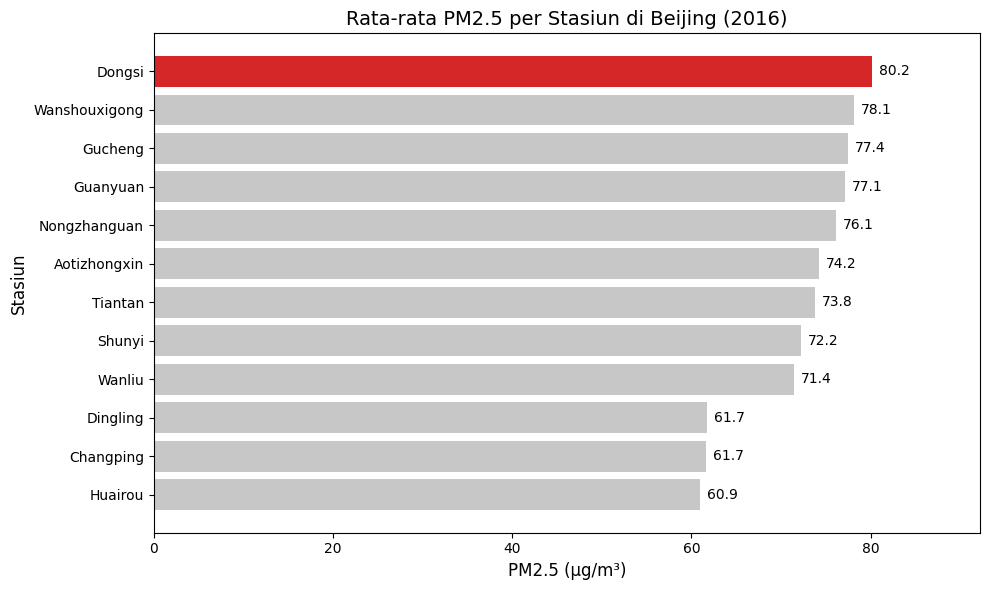

In [9]:
data = pm_station.sort_values(ascending=True)
colors = ["#d62728" if s == data.idxmax() else "#c7c7c7" for s in data.index]

plt.figure(figsize=(10, 6))
bars = plt.barh(data.index, data.values, color=colors)
plt.title("Rata-rata PM2.5 per Stasiun di Beijing (2016)", fontsize=14)
plt.xlabel("PM2.5 (µg/m³)", fontsize=12)
plt.ylabel("Stasiun", fontsize=12)
plt.xlim(0, data.max() * 1.15)

for bar in bars:
    plt.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.1f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

**Insight:**
- Dongsi menjadi stasiun dengan rata-rata PM2.5 tertinggi pada 2016 (80,2 µg/m³), sedangkan Huairou terendah (60,9 µg/m³), selisihnya sekitar 19,3 µg/m³.
- Stasiun terbagi menjadi dua kelompok: sembilan stasiun berada di kisaran 71-80 µg/m³, sedangkan Dingling, Changping, dan Huairou berada di kisaran 61-62 µg/m³.
- Seluruh stasiun masih jauh di atas pedoman tahunan WHO (5 µg/m³), sehingga seluruh wilayah tetap perlu perhatian, dengan prioritas pada stasiun tertinggi.

### Pertanyaan 2: Pada jam berapa dan di musim apa rata-rata PM2.5 paling tinggi selama Maret 2013 sampai Februari 2017, dan berapa selisihnya dibanding jam dan musim terendah?

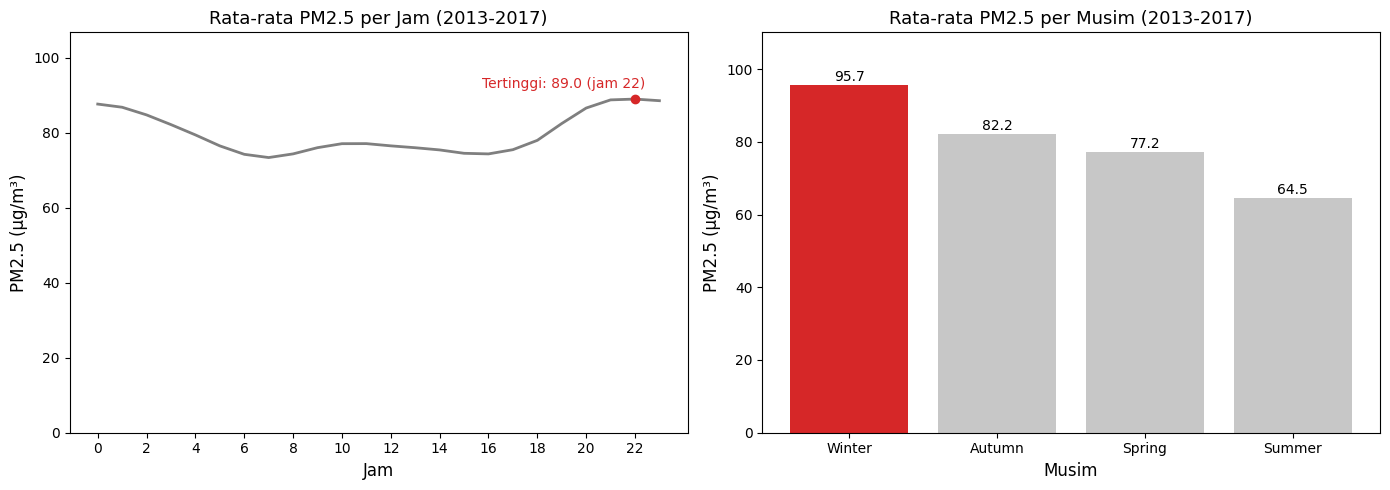

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: rata-rata PM2.5 per jam
axes[0].plot(pm_hour.index, pm_hour.values, color="#7f7f7f", linewidth=2)
axes[0].scatter(pm_hour.idxmax(), pm_hour.max(), color="#d62728", zorder=3)
axes[0].annotate(f"Tertinggi: {pm_hour.max():.1f} (jam {pm_hour.idxmax()})",
                 (pm_hour.idxmax(), pm_hour.max()), textcoords="offset points",
                 xytext=(-110, 8), fontsize=10, color="#d62728")
axes[0].set_title("Rata-rata PM2.5 per Jam (2013-2017)", fontsize=13)
axes[0].set_xlabel("Jam", fontsize=12)
axes[0].set_ylabel("PM2.5 (µg/m³)", fontsize=12)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_ylim(0, pm_hour.max() * 1.2)

# Grafik 2: rata-rata PM2.5 per musim
season_colors = ["#d62728" if s == pm_season.idxmax() else "#c7c7c7" for s in pm_season.index]
bars = axes[1].bar(pm_season.index, pm_season.values, color=season_colors)
axes[1].set_title("Rata-rata PM2.5 per Musim (2013-2017)", fontsize=13)
axes[1].set_xlabel("Musim", fontsize=12)
axes[1].set_ylabel("PM2.5 (µg/m³)", fontsize=12)
axes[1].set_ylim(0, pm_season.max() * 1.15)
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f"{bar.get_height():.1f}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata PM2.5 tertinggi terjadi pada jam 22.00 (89,0 µg/m³) dan terendah pada jam 07.00 (73,4 µg/m³), selisihnya sekitar 15,6 µg/m³.
- Pola harian menunjukkan PM2.5 tinggi pada malam hingga dini hari, turun hingga pagi, lalu naik lagi mulai sore hari.
- Winter menjadi musim dengan PM2.5 tertinggi (95,7 µg/m³), sedangkan Summer terendah (64,5 µg/m³), selisihnya sekitar 31,2 µg/m³.
- Perbedaan antar musim (sekitar 31 µg/m³) hampir dua kali lipat perbedaan antar jam (sekitar 16 µg/m³), sehingga musim berpengaruh lebih besar dibanding jam.

## Analisis Lanjutan (binning)

Analisis lanjutan yang digunakan adalah **binning (manual grouping)**, yaitu mengelompokkan nilai PM2.5 ke dalam kategori kualitas udara (Baik, Sedang, Tidak Sehat bagi Kelompok Sensitif, Tidak Sehat, Sangat Tidak Sehat, Berbahaya) berdasarkan standar AQI US EPA.

Tujuannya adalah mengubah angka konsentrasi PM2.5 menjadi kategori yang lebih mudah dipahami dampaknya bagi kesehatan, serta membandingkan proporsi jam dengan kualitas udara buruk di tiap stasiun. Teknik ini relevan karena melengkapi dua pertanyaan bisnis, yaitu perbandingan antar stasiun dan pola waktu.

In [11]:
bins = [0, 12, 35.4, 55.4, 150.4, 250.4, np.inf]
labels = ["Baik", "Sedang", "Tidak Sehat bagi Kelompok Sensitif",
          "Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"]
df["kategori_pm25"] = pd.cut(df["PM2.5"], bins=bins, labels=labels, include_lowest=True)

kategori_station = (pd.crosstab(df["station"], df["kategori_pm25"], normalize="index") * 100).round(1)
kategori_station

kategori_pm25,Baik,Sedang,Tidak Sehat bagi Kelompok Sensitif,Tidak Sehat,Sangat Tidak Sehat,Berbahaya
station,,,,,,
Aotizhongxin,13.4,22.1,13.0,35.5,11.2,4.8
Changping,15.8,26.6,13.1,31.9,9.4,3.2
Dingling,22.6,23.7,12.6,29.2,8.6,3.3
Dongsi,14.3,20.2,12.4,36.0,11.6,5.5
Guanyuan,12.2,22.3,13.3,36.4,11.1,4.6
Gucheng,13.4,20.4,13.6,36.7,11.1,4.8
Huairou,17.6,24.7,13.2,32.6,9.0,2.8
Nongzhanguan,14.7,20.9,12.6,34.9,11.4,5.6
Shunyi,16.3,21.7,12.4,34.3,10.8,4.5


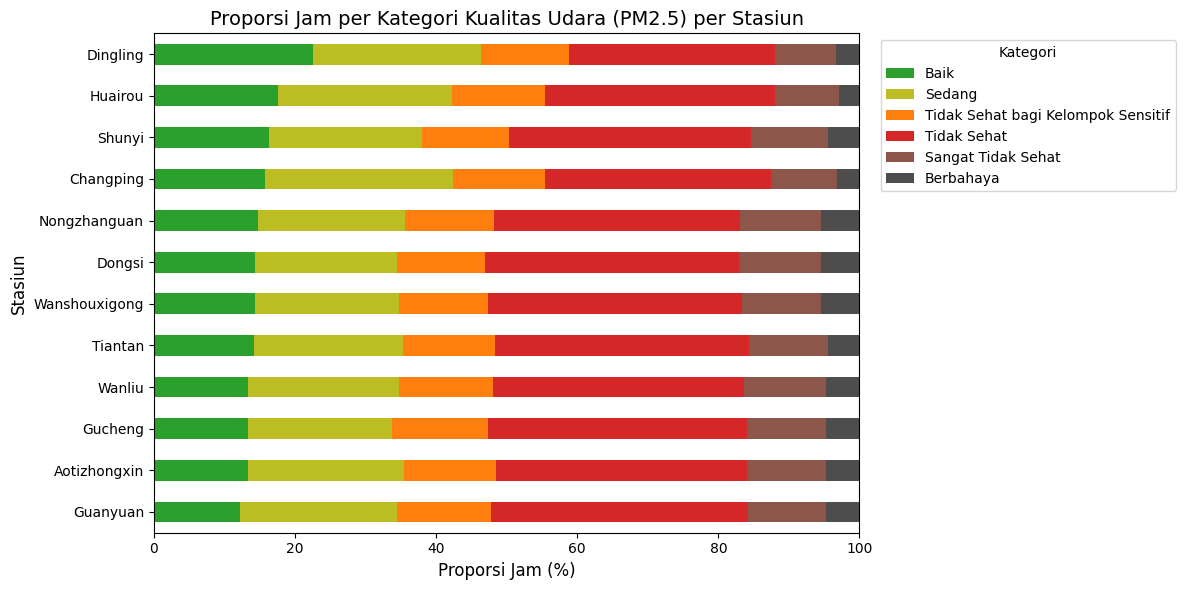

In [12]:
colors = ["#2ca02c", "#bcbd22", "#ff7f0e", "#d62728", "#8c564b", "#4d4d4d"]
kategori_station.sort_values("Baik").plot(kind="barh", stacked=True, figsize=(12, 6), color=colors)
plt.title("Proporsi Jam per Kategori Kualitas Udara (PM2.5) per Stasiun", fontsize=14)
plt.xlabel("Proporsi Jam (%)", fontsize=12)
plt.ylabel("Stasiun", fontsize=12)
plt.xlim(0, 100)
plt.legend(title="Kategori", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Insight:**
- Pengelompokan dilakukan pada nilai PM2.5 per jam menggunakan batas kategori AQI US EPA sebagai pendekatan.
- Proporsi jam dengan kategori "Tidak Sehat" atau lebih buruk (Tidak Sehat + Sangat Tidak Sehat + Berbahaya) mencapai 41% sampai 53% di seluruh stasiun. Tertinggi di Dongsi (sekitar 53,1%) dan terendah di Dingling (sekitar 41,1%).
- Proporsi jam dengan kategori "Baik" hanya 12,2% sampai 22,6%. Tertinggi di Dingling (22,6%) dan terendah di Guanyuan (12,2%).
- Kategori "Berbahaya" paling sering muncul di Nongzhanguan (5,6%) dan Dongsi (5,5%), sedangkan paling jarang di Huairou (2,8%).
- Stasiun di pinggiran (Dingling, Huairou, Changping) punya proporsi jam kualitas udara buruk yang lebih rendah dibanding stasiun lainnya, sejalan dengan hasil Pertanyaan 1.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada tahun 2016, Dongsi menjadi stasiun dengan rata-rata PM2.5 tertinggi (80,2 µg/m³), sedangkan Huairou terendah (60,9 µg/m³), dengan selisih sekitar 19,3 µg/m³. Seluruh stasiun masih jauh di atas pedoman tahunan WHO (5 µg/m³).
- **Conclusion pertanyaan 2:** Selama Maret 2013 sampai Februari 2017, PM2.5 tertinggi terjadi pada pukul 22.00 (89,0 µg/m³) dan terendah pukul 07.00 (73,4 µg/m³), selisih sekitar 15,6 µg/m³. Musim Winter menjadi yang tertinggi (95,7 µg/m³) dan Summer terendah (64,5 µg/m³), selisih sekitar 31,2 µg/m³.

**Rekomendasi Action Item:**
- Memprioritaskan upaya pengendalian polusi di wilayah sekitar stasiun dengan PM2.5 tertinggi seperti Dongsi, Wanshouxigong, dan Gucheng.
- Memperketat pengendalian emisi pada musim Winter, misalnya terkait pemanasan dan aktivitas kendaraan, karena PM2.5 paling tinggi pada musim ini.
- Menyarankan masyarakat menghindari aktivitas luar ruangan pada malam hari (sekitar pukul 20.00-23.00) dan lebih memilih pagi hingga siang hari saat PM2.5 relatif lebih rendah.
- Memberikan peringatan kualitas udara kepada kelompok sensitif, terutama di stasiun dengan proporsi jam kategori tidak sehat di atas 50%.

In [13]:
import os
os.makedirs("dashboard", exist_ok=True)

main_data = (df.groupby(["station", "year", "month", "hour", "season", "kategori_pm25"], observed=True)["PM2.5"]
               .agg(jumlah_jam="count", total_pm25="sum")
               .reset_index())
main_data.to_csv("dashboard/main_data.csv", index=False)
print(main_data.shape)
main_data.head()

(73483, 8)


,station,year,month,hour,season,kategori_pm25,jumlah_jam,total_pm25
0,Aotizhongxin,2013,3,0,Spring,Baik,3,21.0
1,Aotizhongxin,2013,3,0,Spring,Sedang,4,91.0
2,Aotizhongxin,2013,3,0,Spring,Tidak Sehat bagi Kelompok Sensitif,2,91.0
3,Aotizhongxin,2013,3,0,Spring,Tidak Sehat,14,1200.0
4,Aotizhongxin,2013,3,0,Spring,Sangat Tidak Sehat,4,783.0
